# Function 3 - Week 5: exploration review

Review measured outputs and input coverage in the independent Week 5 `observations.csv`, including the confirmed Week 4 return received on **23 October 2026**.

The saved exploration shortlist is complete; a new Week 5 query requires a separate decision. Descriptive plots and the three-input output cloud follow the Week 4 pattern. Continue in [model predictions](model_predictions.ipynb) for fresh validation and a proposed Week 5 input. The [Week 4 model notebook](../Week_04/model_predictions.ipynb) remains historical.


In [2]:
# Imports & shared helpers
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import sys

# Find Shared from any function/week folder inside notebooks.
shared_dir = next(
    (folder / "Shared"
     for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "plot_helpers.py").is_file()),
    None,
)
if shared_dir is None:
    raise FileNotFoundError(
        "Cannot find Shared/plot_helpers.py above the working directory. "
        "Run this notebook from within the notebooks folder."
    )
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from plot_helpers import (
    PLOT_CONFIG,
    plot_sampling_gap_projections,
    plot_output_number_line,
)
from output_helpers import summarise_output_observations


In [3]:
# Data and output paths for this week's notebook.
# Start the kernel with this notebook's folder as its working directory.
week_dir = Path.cwd().resolve()
full_data_path = week_dir / "observations.csv"

if not (week_dir / "exploration-review.ipynb").is_file() or not full_data_path.is_file():
    raise FileNotFoundError(
        "Run this notebook with its own folder as the working directory; "
        "exploration-review.ipynb and observations.csv must be together."
    )

figures = week_dir / "figures"
figures.mkdir(parents=True, exist_ok=True)



In [4]:
# Basic data load
print(f"Loading data from: {full_data_path}")
data = pd.read_csv(full_data_path, float_precision="round_trip")

Loading data from: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\stage-2-bbo\notebooks\Function_3\Week_05\observations.csv


In [5]:
# Column inspection
columns = data.columns
print("Columns: ", columns)

Columns:  Index(['observation_id', 'source_round', 'x1', 'x2', 'x3', 'y'], dtype='str')


In [6]:
# Where we pray for good data, aka checking for nulls
print (data.isna().sum())

observation_id    0
source_round      0
x1                0
x2                0
x3                0
y                 0
dtype: int64


In [7]:
# Prepare observation labels for the exploration plots
plot_data = data.copy()
plot_data["rank"] = (
    plot_data["y"]
    .rank(ascending=False, method="min")
    .astype(int)
)

In [8]:
# Splitting our data into inputs X and outputs y
output_column = "y"
# The course names inputs x1, x2, ...; preserve their CSV column order.
input_columns = [
    name for name in data.columns
    if name.startswith("x") and name[1:].isdigit()
]

#print("Input columns: ", input_columns)
#print("Output column: ", output_column)

X = data[input_columns]
y = data[output_column]

#print("The inputs are given by :")
#print(X.head())
#print("The outputs are given by :")
#print(y[:5])


In [9]:
# So now we have:

# data	       = Observations as loaded from the CSV
# X, y	       = Inputs and outputs selected from those observations
# plot_data	   = A separate copy enriched for the exploration plots

In [10]:
# Review the latest recorded submission against earlier observed outputs.
output_review = summarise_output_observations(
    data,
    input_columns=input_columns,
    output_column=output_column,
)
print(output_review["report"])


Latest recorded submission: round 4 (1 new output).
Compared with 18 earlier observations (19 outputs in total).
Earlier output range: [-0.398925513146, -0.0348353133501].

round-04: y = -0.0566421241758 (negative); rank 8/19 (1 = highest output).
Inputs: x1 = 0.903842, x2 = 0.268903, x3 = 0.8752
Within the earlier output range.


The Week 4 return is **-0.0566421241758**, ranked **8/19 (1 = highest output)**. It does not improve the incumbent of **-0.0348353133501** (initial-004).

## Observed outputs

A linear number line suits Function 3's observed output range. The latest submission is starred;
higher (less negative) outputs lie further to the right.


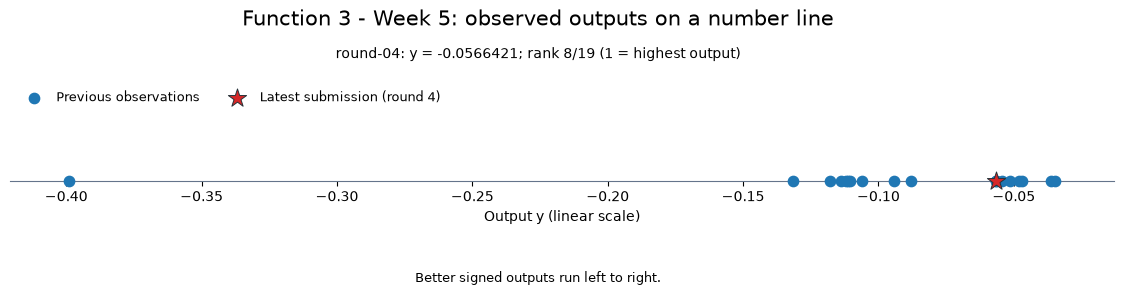

In [11]:
plot_output_number_line(
    output_review,
    title="Function 3 - Week 5: observed outputs on a number line",
    save_to=figures / "output-number-line.png",
)

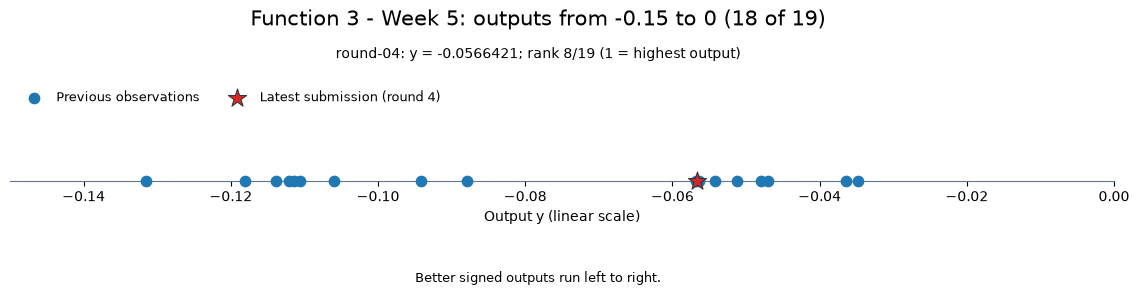

In [12]:
# Keep the original observations and ranks; zoom the display window only.
output_zoom_limits = (-0.15, 0.0)
outputs_in_zoom = int(y.between(*output_zoom_limits).sum())
output_zoom_fig = plot_output_number_line(
    output_review,
    title=f"Function 3 - Week 5: outputs from -0.15 to 0 ({outputs_in_zoom} of {len(y)})",
)
output_zoom_fig.axes[0].set_xlim(*output_zoom_limits)
output_zoom_fig.savefig(figures / "output-number-line-zoom.png", dpi=160)
output_zoom_fig

## Observed ranks and sampling gaps

Numbers are observed output ranks (1 = highest); the latest submission is starred.
All three projections share one colour scale for distance to the nearest observation **in that plane**.
A small projected gap can still hide a gap in the omitted input coordinate.


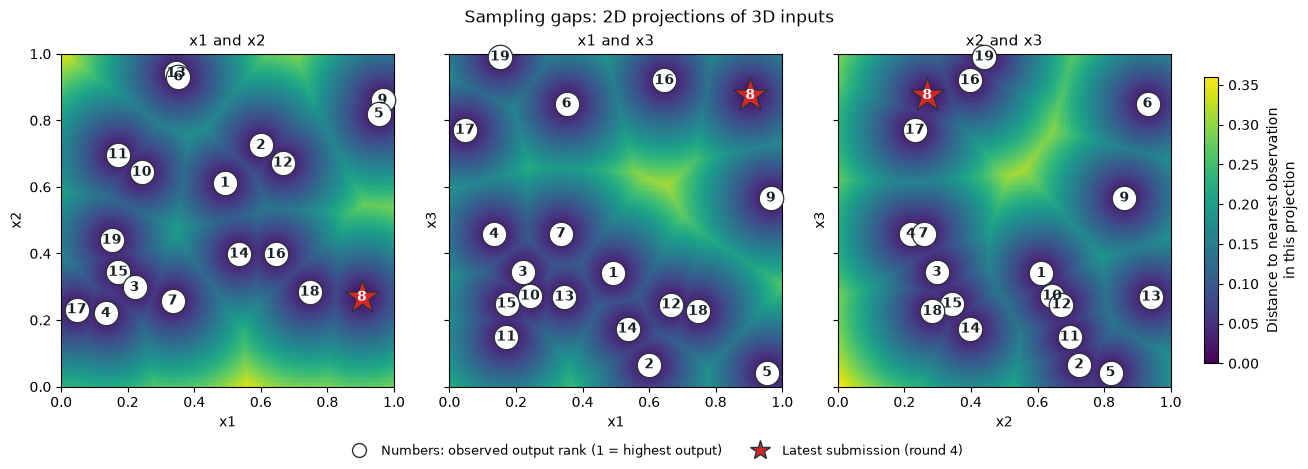

In [13]:
# Compare the three input-pair projections on one shared distance scale.
plot_sampling_gap_projections(
    plot_data,
    input_columns=input_columns,
    highlight=output_review["latest_mask"],
    highlight_label=f"Latest submission (round {output_review['latest_round']})",
    save_to=figures / "sampling-gaps.png",
)

## Three input coordinates, with output shown by colour

A terrain with two ground coordinates and output as height cannot also show a third input.
First keep all three **input axes** and use colour for the measured output. Drag to rotate,
scroll to zoom, and hover over a point for its input coordinates and output.
The gold diamond marks the best observed output; points are not joined into an observed surface.
Raw outputs are suitable here. Negative values retain their signs: closer to zero means a higher score.

The Plasma colour scale runs from dark purple (lower outputs) to bright yellow (higher outputs).


In [14]:
import plotly.graph_objects as go

cloud_plot_config = {**PLOT_CONFIG, "responsive": False}

surface_inputs = X[["x1", "x2", "x3"]].to_numpy(dtype=float)
surface_outputs = y.to_numpy(dtype=float)
best_position = np.argmax(surface_outputs)
terrain_relief = 0.16
observed_input_fig = go.Figure(go.Scatter3d(
    x=X["x1"], y=X["x2"], z=X["x3"], mode="markers",
    marker=dict(size=6, color=surface_outputs, colorscale="Plasma",
                cmin=surface_outputs.min(), cmax=surface_outputs.max(),
                colorbar=dict(title="Observed y"), line=dict(color="black", width=1)),
    customdata=surface_outputs, name="Observed inputs and outputs",
    hovertemplate="x1=%{x:.4f}<br>x2=%{y:.4f}<br>x3=%{z:.4f}"
                  "<br>Observed y=%{customdata:.4f}<extra></extra>",
))
observed_input_fig.add_trace(go.Scatter3d(
    x=[surface_inputs[best_position, 0]], y=[surface_inputs[best_position, 1]],
    z=[surface_inputs[best_position, 2]], mode="markers",
    marker=dict(size=9, color="gold", symbol="diamond", line=dict(color="black", width=2)),
    customdata=[surface_outputs[best_position]], name="Best observed output",
    hovertemplate="Best observed y=%{customdata:.4f}<extra></extra>",
))
observed_input_fig.update_layout(
    title="Function 3: observed outputs in the three-input space",
    width=850, height=560, autosize=False, margin=dict(l=10, r=80, t=70, b=30),
    scene=dict(xaxis=dict(title="x1", range=[0, 1]),
               yaxis=dict(title="x2", range=[0, 1]),
               zaxis=dict(title="x3 (input)", range=[0, 1]),
               aspectmode="cube", dragmode="orbit"),
    legend=dict(x=0, y=1),
)
observed_input_fig.write_html(
    figures / "observed-input-cloud.html", include_plotlyjs=True, config=cloud_plot_config,
)
print(f"{len(surface_outputs)} observations; raw output range {surface_outputs.min():.4f} to {surface_outputs.max():.4f}.")
observed_input_fig.show(config=cloud_plot_config)


19 observations; raw output range -0.3989 to -0.0348.


### Colour detail: outputs from -0.15 to 0

Use the same output window as the zoomed number line. Colours are rescaled across the
lowest and highest displayed outputs.


In [15]:
# Select a display subset without changing the observations used elsewhere.
cloud_zoom_mask = y.between(*output_zoom_limits).to_numpy()
cloud_zoom_inputs = surface_inputs[cloud_zoom_mask]
cloud_zoom_outputs = surface_outputs[cloud_zoom_mask]

# Copy the original cloud so the axes, camera, palette and hover format match.
observed_input_zoom_fig = go.Figure(observed_input_fig)
observed_input_zoom_fig.data[0].update(
    x=cloud_zoom_inputs[:, 0], y=cloud_zoom_inputs[:, 1], z=cloud_zoom_inputs[:, 2],
    customdata=cloud_zoom_outputs,
    marker=dict(color=cloud_zoom_outputs,
                cmin=cloud_zoom_outputs.min(), cmax=cloud_zoom_outputs.max(),
                colorbar=dict(title="Observed y<br>(displayed range)")),
)
zoom_best_position = np.argmax(cloud_zoom_outputs)
observed_input_zoom_fig.data[1].update(
    x=[cloud_zoom_inputs[zoom_best_position, 0]],
    y=[cloud_zoom_inputs[zoom_best_position, 1]],
    z=[cloud_zoom_inputs[zoom_best_position, 2]],
    customdata=[cloud_zoom_outputs[zoom_best_position]],
    name="Best output in this view",
)
observed_input_zoom_fig.update_layout(
    title=f"Function 3: outputs from -0.15 to 0 ({len(cloud_zoom_outputs)} of {len(surface_outputs)})",
)
cloud_zoom_html = figures / "observed-input-cloud-zoom.html"
observed_input_zoom_fig.write_html(cloud_zoom_html, include_plotlyjs=True, config=cloud_plot_config)
print(f"{len(cloud_zoom_outputs)} of {len(surface_outputs)} observations; colours rescaled from "
      f"{cloud_zoom_outputs.min():.4f} to {cloud_zoom_outputs.max():.4f}.")
observed_input_zoom_fig.show(config=cloud_plot_config)

18 of 19 observations; colours rescaled from -0.1315 to -0.0348.


## Completed exploration plan

In [16]:
# Fixed Week 2 plan, preserved at full precision; no optimisation is run.
planned_queries = pd.DataFrame(
    [[0.9545240919577334, 0.8194703192896731, 0.04216282607444466], [0.3523200058361702, 0.9307991516470914, 0.8498485887799658], [0.9038419399841349, 0.2689031599827457, 0.8751995976599097]],
    columns=input_columns,
)

# The saved sequence starts in Week 2; keep only this week's unevaluated remainder.
current_week = int(week_dir.name.removeprefix("Week_"))
coverage_queries = planned_queries.iloc[current_week - 2:].copy()


### Fixed exploration progression

Rows show the three input-pair projections; columns follow the saved plan from Week 2
through its completion after Week 5. All panels share one projected-distance scale.
All observed inputs are included, including the point omitted from the zoomed output views.


In [17]:
# Show the saved exploration plan across all three input-pair projections.
def plot_projected_plan_storyboard(observations, plan, *, current_week,
                                   first_plan_week=2, save_to=None):
    from itertools import combinations
    from matplotlib.colors import Normalize
    from plot_helpers import plot_sampling_gaps

    columns = list(plan.columns)
    completed = current_week - first_plan_week
    if len(columns) != 3 or plan.empty:
        raise ValueError("Supply a non-empty three-input plan.")
    if completed not in range(len(plan) + 1):
        raise ValueError("current_week must identify a stage of the saved plan.")
    if (observations["source_round"] >= current_week).any():
        raise ValueError("Observed submissions must precede the current week's query.")
    baseline = observations.loc[observations["source_round"] < first_plan_week, columns].copy()
    if baseline.empty:
        raise ValueError("The plan needs earlier observations as a starting point.")

    # Completed steps use recorded inputs, including their submission precision.
    # Only unevaluated steps use the saved planning coordinates.
    stages = [baseline]
    for index, point in enumerate(plan.to_numpy(dtype=float)):
        week = first_plan_week + index
        if index < completed:
            addition = observations.loc[observations["source_round"] == week, columns].copy()
            if len(addition) != 1 or not np.allclose(addition.to_numpy()[0], point, rtol=0, atol=5e-7):
                raise ValueError(f"Week {week}'s recorded input does not match the saved plan.")
        else:
            addition = pd.DataFrame([point], columns=columns)
        stages.append(pd.concat([stages[-1], addition], ignore_index=True))

    pairs = list(combinations(columns, 2))
    figure, axes = plt.subplots(len(pairs), len(stages), figsize=(14, 9.4),
                                sharex=True, sharey=True, squeeze=False, layout="constrained")
    meshes = []
    for row, pair in enumerate(pairs):
        for column, stage in enumerate(stages):
            axis = axes[row, column]
            plot_sampling_gaps(stage, pair=pair, ax=axis, show_labels=False,
                               show_legend=False, show_colorbar=False)
            meshes.append(axis.collections[0])
            dots = axis.collections[1]
            dots.set_sizes([18])
            dots.set_linewidths([0.6])
            dots.set_clip_on(False)
            dots.set_in_layout(False)
            axis.set(xticks=[0, 0.5, 1], yticks=[0, 0.5, 1])
            axis.tick_params(labelsize=8)
            axis.set_ylabel(pair[1] if column == 0 else "")
            if row == 0:
                last_week = first_plan_week + len(plan) - 1
                title = (f"Week {first_plan_week + column} start" if column < len(plan)
                         else f"After Week {last_week}")
                if column == completed:
                    title += "\nCurrent Position"
                elif column > completed:
                    title += "\nPlanned"
                axis.set_title(title, fontsize=10,
                               color="#9a3412" if column == completed else "#172126",
                               fontweight="bold" if column == completed else "normal")
            else:
                axis.set_title("")
            if column == completed:
                for spine in axis.spines.values():
                    spine.set_edgecolor("#c2410c")
                    spine.set_linewidth(2.5)

    # Adding observations cannot increase nearest-point distances, so the
    # largest starting gap across the projections fixes the scale everywhere.
    starting_meshes = meshes[::len(stages)]
    norm = Normalize(vmin=0, vmax=max(float(mesh.get_array().max()) for mesh in starting_meshes))
    for mesh in meshes:
        mesh.set_norm(norm)
    figure.colorbar(meshes[0], ax=axes.ravel().tolist(), shrink=0.85, fraction=0.025, pad=0.02,
                    label="Distance to nearest observation in this projection")
    if save_to is not None:
        figure.savefig(save_to, dpi=160)
    plt.close(figure)
    return figure


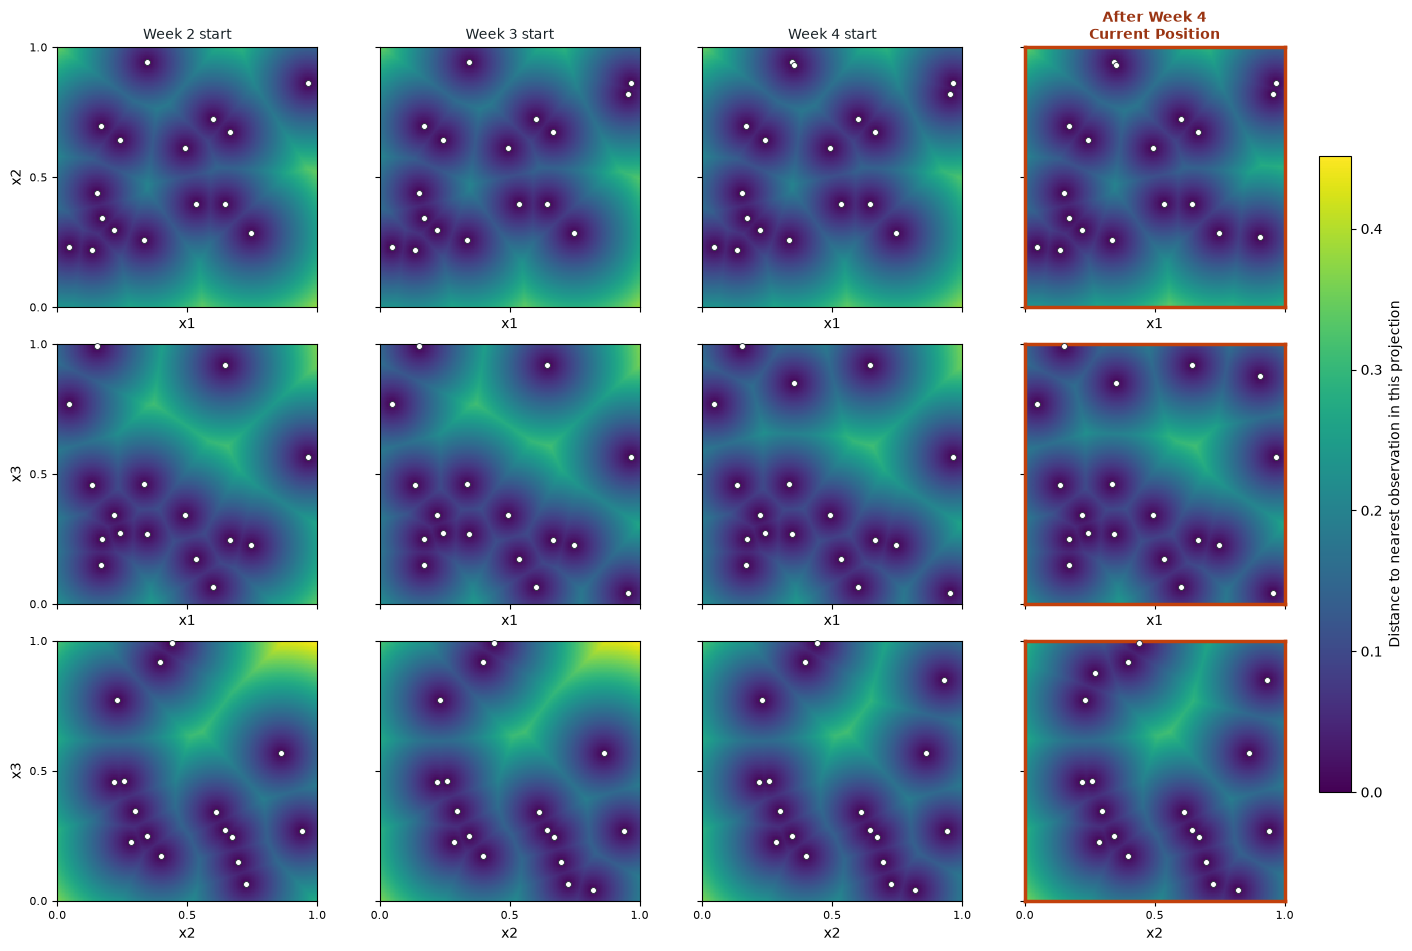

In [18]:
projected_storyboard_fig = plot_projected_plan_storyboard(
    data, planned_queries,
    current_week=current_week,
    save_to=figures / "fixed-exploration-progression-projections.png",
)
projected_storyboard_fig

In [19]:
# Copy the portal-ready input from the row for the required week.
remaining_queries = coverage_queries.copy()
remaining_queries.index = pd.Index(
    range(current_week, current_week + len(remaining_queries)), name="Week",
)
remaining_queries["Portal input"] = [
    "-".join(f"{value:.6f}" for value in point)
    for point in coverage_queries.to_numpy()
]
if remaining_queries.empty:
    print("The saved Week 2 exploration plan is complete. No Week 5 input is selected here.")
else:
    display(remaining_queries.style.format({column: "{:.6f}" for column in input_columns}))

The saved Week 2 exploration plan is complete. No Week 5 input is selected here.


## Continue with model predictions

The saved exploration shortlist is complete. This notebook closes the fixed-plan observation
review; that does not establish that exploration of the unknown function is complete.

Continue in [model predictions](model_predictions.ipynb) to compare methods, inspect three-input
predictions and uncertainty, and review a proposed next point. Both notebooks load the same
independent **19-observation snapshot through round 4**. No Week 5 submission is recorded here.
